# Teammate 1: label and speed checks

This notebook uses only training trips. Run all cells to create the figures and conclusions used for Teammate 1's review.

It checks whether reference labels follow the GPS trace and whether unusually high speeds look related to timestamp gaps or GPS jumps.

In [1]:
from pathlib import Path
import sys

def find_project_root(start):
    locations = [start, *start.parents]
    locations.extend(location / 'ML-Hackathon' for location in [start, *start.parents])
    for location in locations:
        if (location / 'pathsnap').is_dir() and (location / 'data').is_dir():
            return location
    raise RuntimeError(f'Could not find ML-Hackathon from: {start}')

# Find the repository so the notebook works from the project or notebooks folder.
ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(ROOT))
RESULTS_DIR = ROOT / 'results' / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f'Project root: {ROOT}')

Project root: D:\ML-Hackathon-PathSnap\ML-Hackathon


## Label sanity check

The selected trips include the required parked-vehicle and reference examples, one route-break trip from the EDA output, a long-gap trip, and trips from different map areas.

In [2]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection

from pathsnap.data import list_trips, load_trip
from pathsnap.labels import derive_ref_arcs

# Use the EDA route-continuity check to choose a trip with a route break.
available_train_ids = set(list_trips('train'))
eda_summary_path = ROOT / 'results' / 'eda' / 'trip_summary.csv'
if not eda_summary_path.exists():
    raise FileNotFoundError('Run notebooks/01_eda.ipynb before this notebook.')

eda_summary = pd.read_csv(eda_summary_path, dtype={'trip_id': str})
route_breaks = eda_summary.loc[eda_summary['disconnected_route_transitions'] > 0]
route_break_id = route_breaks.sort_values('disconnected_route_transitions', ascending=False).iloc[0]['trip_id']
requested_ids = ['00000054', '00000033', '00000002', route_break_id, '00000057', '00000090', '00000095']
label_trip_ids = list(dict.fromkeys(trip_id for trip_id in requested_ids if trip_id in available_train_ids))
print(f'Route-break trip selected from EDA: {route_break_id}')
print(f'Label-check trips: {label_trip_ids}')

Route-break trip selected from EDA: 00000019
Label-check trips: ['00000054', '00000033', '00000002', '00000019', '00000057', '00000090', '00000095']


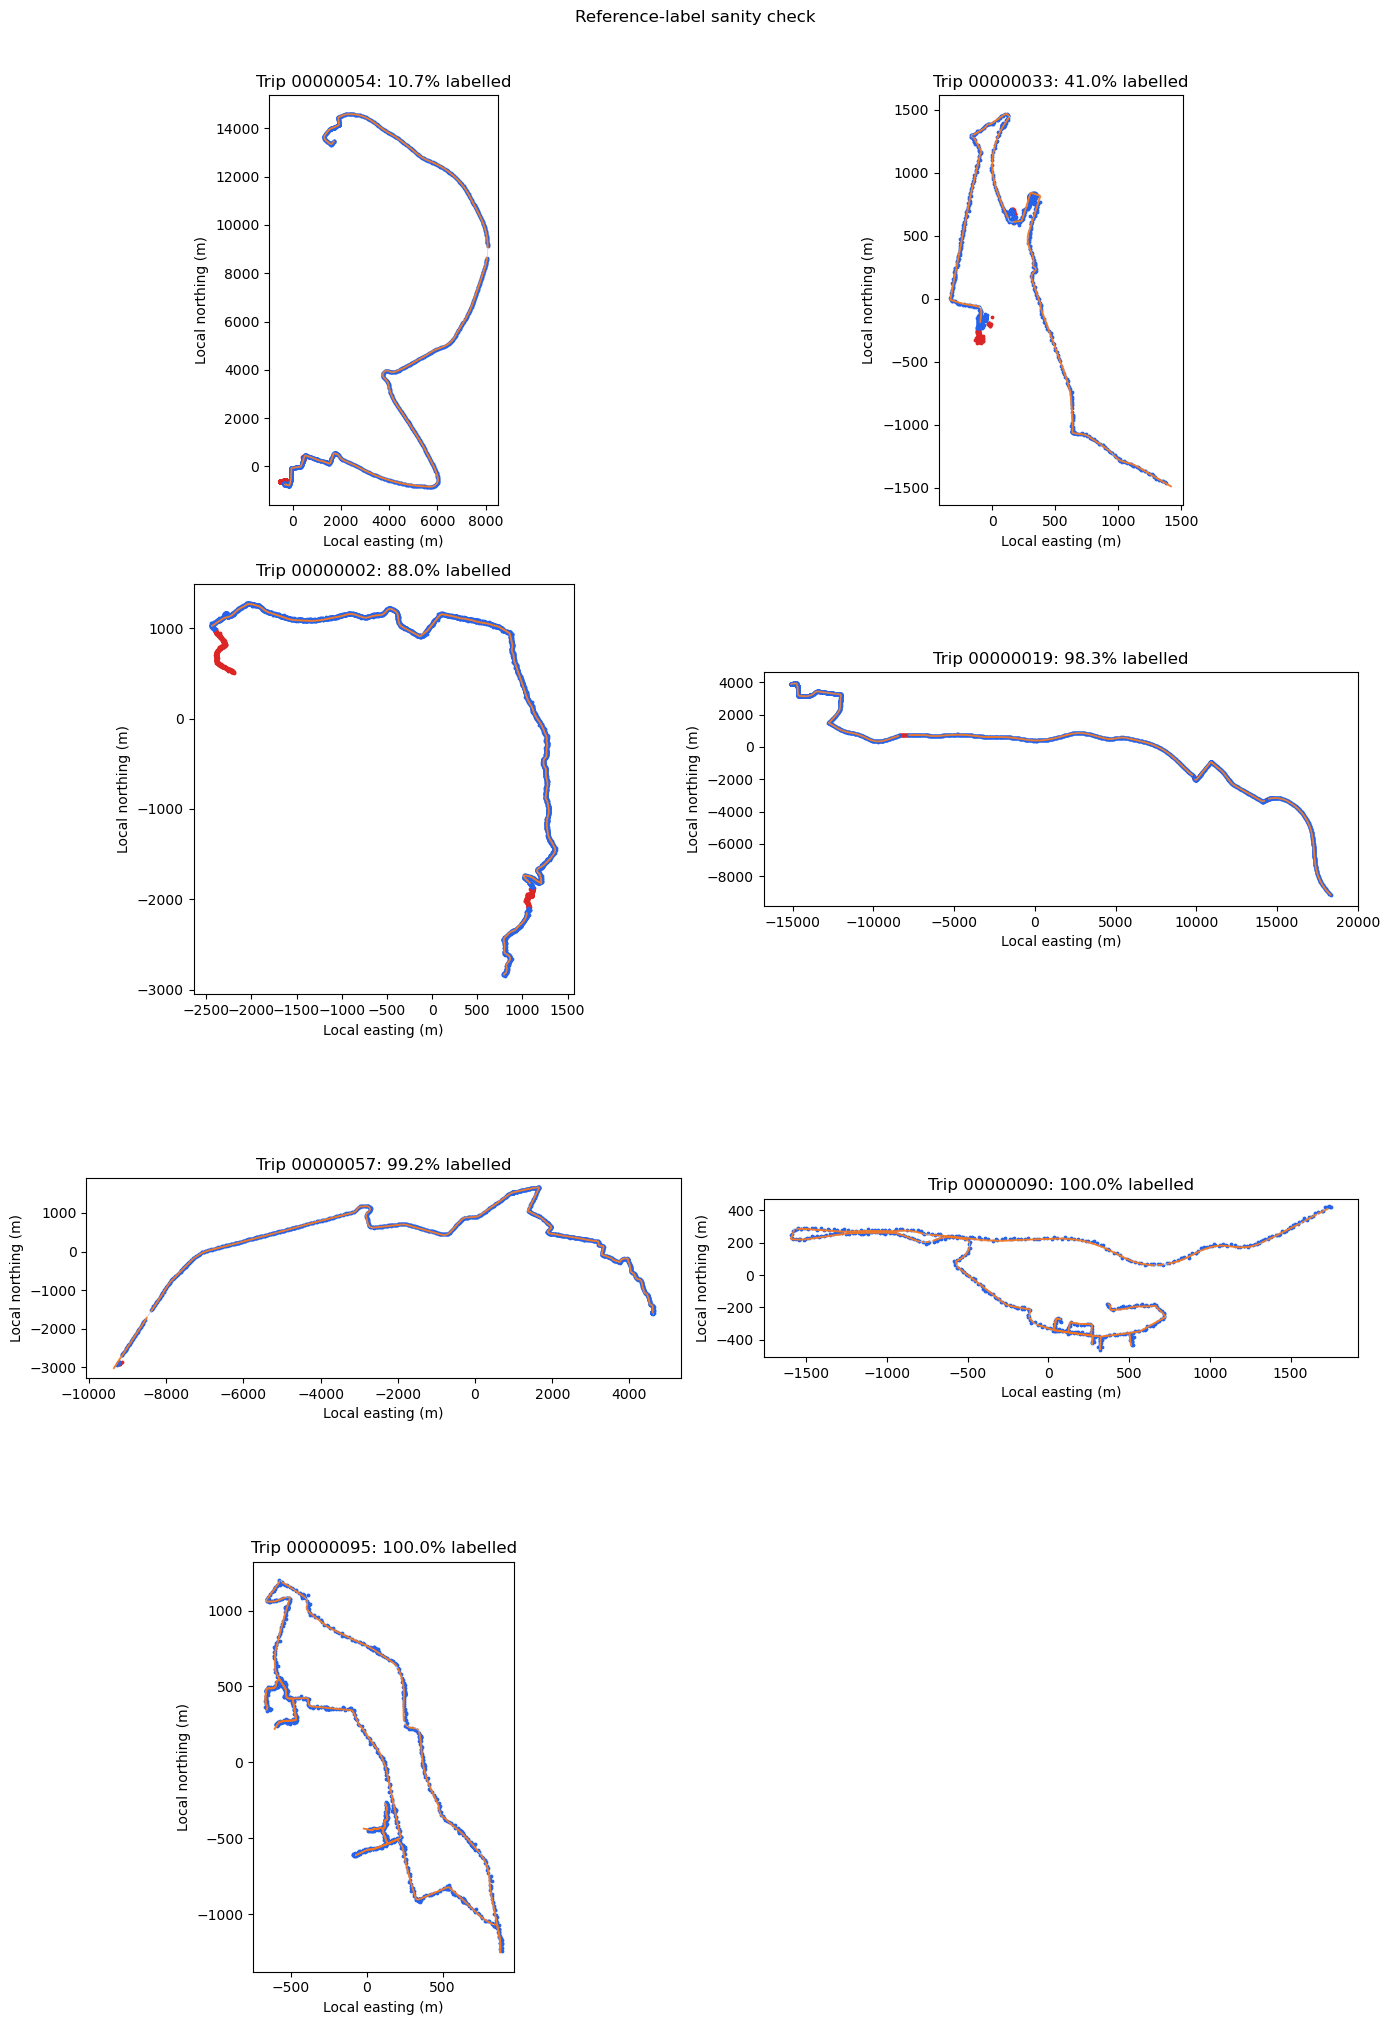

,trip_id,gps_points,labelled_points,labelled_share,p95_label_distance_m,unknown_points
0,00000054,19313,2073,0.107337,215.465042,17240
1,00000033,5844,2395,0.409822,142.068024,3449
2,00000002,7243,6375,0.880160,255.256165,868
3,00000019,2354,2315,0.983432,15.386872,39
4,00000057,1645,1632,0.992097,16.887997,13
5,00000090,536,536,1.000000,12.773892,0
6,00000095,1551,1551,1.000000,12.453629,0


Conclusion: inspect the orange labelled arcs against blue GPS traces. Red points are intentionally unknown because they exceed the label-distance threshold.


In [3]:
# Orange segments are the inferred reference arcs. Red GPS points are intentionally unknown labels.
label_rows = []
fig, axes = plt.subplots(math.ceil(len(label_trip_ids) / 2), 2, figsize=(14, 5 * math.ceil(len(label_trip_ids) / 2)))
for axis, trip_id in zip(axes.flat, label_trip_ids):
    trip = load_trip('train', trip_id)
    ref_labels = derive_ref_arcs(trip)
    known = ref_labels.ref_arc >= 0
    nodes_xy = trip.nodes_xy()
    track_xy = trip.track_xy()
    route_segments = nodes_xy[trip.arcs[trip.route]]
    axis.add_collection(LineCollection(route_segments, colors='#cbd5e1', linewidths=0.6))
    if known.any():
        labelled_segments = nodes_xy[trip.arcs[np.unique(ref_labels.ref_arc[known])]]
        axis.add_collection(LineCollection(labelled_segments, colors='#f97316', linewidths=1.4, alpha=0.9))
    axis.scatter(track_xy[~known, 0], track_xy[~known, 1], s=3, color='#dc2626', label='Unknown label')
    axis.scatter(track_xy[known, 0], track_xy[known, 1], s=3, color='#2563eb', label='Labelled GPS')
    axis.set_aspect('equal')
    axis.set_title(f'Trip {trip_id}: {known.mean():.1%} labelled')
    axis.set_xlabel('Local easting (m)')
    axis.set_ylabel('Local northing (m)')
    label_rows.append({
        'trip_id': trip_id,
        'gps_points': len(trip.track),
        'labelled_points': int(known.sum()),
        'labelled_share': float(known.mean()),
        'p95_label_distance_m': float(np.percentile(ref_labels.dist_m, 95)),
        'unknown_points': int((~known).sum()),
    })
for axis in axes.flat[len(label_trip_ids):]:
    axis.remove()
fig.suptitle('Reference-label sanity check', y=1.01)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'teammate1_label_sanity.png', dpi=180, bbox_inches='tight')
plt.show()

label_summary = pd.DataFrame(label_rows)
display(label_summary)
print('Conclusion: inspect the orange labelled arcs against blue GPS traces. Red points are intentionally unknown because they exceed the label-distance threshold.')

## High-speed-trip review

Speed uses the same two-point central window as candidate generation. The notebook lists every training trip with a 95th-percentile speed above 40 m/s, then plots speed and timestamp gaps for review.

In [4]:
# Match the candidate builder's two-point central window when calculating speed.
def point_speeds(trip, half_window=2):
    points = trip.track_xy()
    timestamps = trip.track[:, 2]
    indices = np.arange(len(points))
    left = np.clip(indices - half_window, 0, len(points) - 1)
    right = np.clip(indices + half_window, 0, len(points) - 1)
    elapsed = np.maximum(timestamps[right] - timestamps[left], 1e-6)
    return np.linalg.norm(points[right] - points[left], axis=1) / elapsed

speed_rows = []
speed_series = {}
for trip_id in sorted(available_train_ids):
    trip = load_trip('train', trip_id, with_route=False)
    speed = point_speeds(trip)
    speed_series[trip_id] = (trip.track[:, 2], speed)
    gaps = np.diff(trip.track[:, 2])
    speed_rows.append({
        'trip_id': trip_id,
        'p95_speed_mps': float(np.percentile(speed, 95)),
        'max_speed_mps': float(speed.max()),
        'gaps_over_1_5s': int((gaps > 1.5).sum()),
        'max_gap_s': float(gaps.max()),
    })

speed_summary = pd.DataFrame(speed_rows).sort_values('p95_speed_mps', ascending=False)
fast_trips = speed_summary.loc[speed_summary['p95_speed_mps'] > 40].copy()
display(fast_trips)
print(f'Found {len(fast_trips)} trips above 40 m/s at the 95th percentile.')

,trip_id,p95_speed_mps,max_speed_mps,gaps_over_1_5s,max_gap_s
25,00000032,61.204546,66.181116,98,41.0
0,00000001,53.724660,57.247386,25,16.0
18,00000024,47.074399,57.857895,23,458.0
10,00000013,42.260720,102.869516,93,8.0


Found 4 trips above 40 m/s at the 95th percentile.


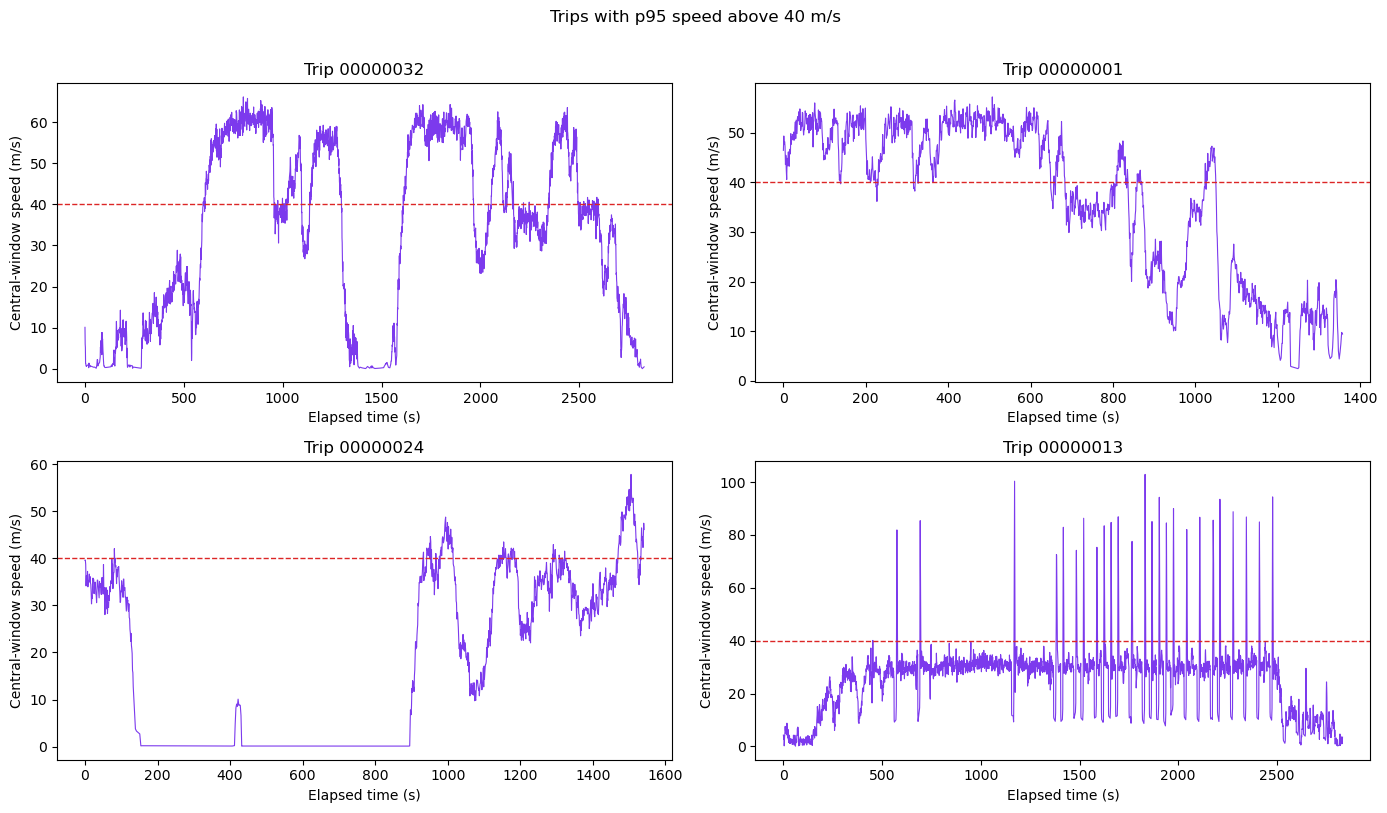

Conclusion: 4 of 4 reviewed trips contain timestamp gaps. Use the plots to distinguish gaps or GPS jumps from sustained high-speed travel.


In [5]:
# Plot up to eight trips, as requested in the training task.
review_ids = fast_trips['trip_id'].head(8).tolist()
fig, axes = plt.subplots(math.ceil(max(1, len(review_ids)) / 2), 2, figsize=(14, 4 * math.ceil(max(1, len(review_ids)) / 2)))
for axis, trip_id in zip(np.ravel(axes), review_ids):
    timestamps, speed = speed_series[trip_id]
    axis.plot(timestamps - timestamps[0], speed, color='#7c3aed', linewidth=0.8)
    axis.axhline(40, color='#dc2626', linestyle='--', linewidth=1)
    axis.set_title(f'Trip {trip_id}')
    axis.set_xlabel('Elapsed time (s)')
    axis.set_ylabel('Central-window speed (m/s)')
for axis in np.ravel(axes)[len(review_ids):]:
    axis.remove()
fig.suptitle('Trips with p95 speed above 40 m/s', y=1.01)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'teammate1_high_speed_review.png', dpi=180, bbox_inches='tight')
plt.show()

if fast_trips.empty:
    print('Conclusion: no training trip crossed the 40 m/s review threshold.')
else:
    with_gaps = int((fast_trips['gaps_over_1_5s'] > 0).sum())
    print(f'Conclusion: {with_gaps} of {len(fast_trips)} reviewed trips contain timestamp gaps. Use the plots to distinguish gaps or GPS jumps from sustained high-speed travel.')